# SVM paso a paso con *Breast Cancer Wisconsin*
**EST852 Machine Learning · Support Vector Machines**

Ejemplo guiado para mostrar en clase. Cada paso tiene el mismo formato:

> **Objetivo** → **Predicción** (la hacen ustedes antes de ejecutar) → **Código** → **Qué observar**

| Paso | Tema | Lámina |
|---|---|---|
| 1–2 | Datos, partición y línea base | 4 |
| 3 | Por qué estandarizar | 29 |
| 4 | Margen y vectores soporte | 17–22 |
| 5 | Efecto de C | 25–27 |
| 6 | El dual en acción | 20–21 |
| 7 | Kernel RBF y gamma | 14–16, 28 |
| 8 | Búsqueda de hiperparámetros | 29–30 |
| 9 | Evaluación final | 32 |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

SEMILLA = 0
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})

## Paso 1. Los datos
**Objetivo.** Conocer el problema: 569 tumores, 30 variables numéricas calculadas sobre imágenes de células (radio, textura, concavidad, etc.), y una etiqueta: maligno o benigno.

**Predicción.** ¿Están las 30 variables en la misma escala? ¿Qué pasará con un kernel que usa distancias?

In [2]:
datos = load_breast_cancer()
X, y = datos.data, datos.target
print('forma de X:', X.shape)
print('clases:', dict(zip(datos.target_names, np.bincount(y))))

resumen = pd.DataFrame(X, columns=datos.feature_names).describe().T[['min', 'max']]
resumen['razón max/min'] = resumen['max'] / resumen['min']
resumen.sort_values('max').iloc[[0, 1, 2, -3, -2, -1]]

forma de X: (569, 30)
clases: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


,min,max,razón max/min
fractal dimension error,0.000895,0.02984,33.348234
smoothness error,0.001713,0.03113,18.172796
concave points error,0.000000,0.05279,inf
area error,6.802000,542.20000,79.711849
mean area,143.500000,2501.00000,17.428571
worst area,185.200000,4254.00000,22.969762


**Qué observar.** Hay variables con máximos del orden de 0,03 (p. ej. `smoothness error`) y otras del orden de 4000 (`worst area`). Una distancia euclidiana entre dos pacientes casi solo "ve" las variables de escala grande. Esto importa para el paso 3.

## Paso 2. Partición y línea base
**Objetivo.** Separar entrenamiento y prueba **antes de mirar nada más**, y fijar la referencia mínima que cualquier modelo debe superar.

**Predicción.** Si siempre respondemos "benigno", ¿qué exactitud obtenemos?

In [3]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEMILLA)
print('entrenamiento:', Xtr.shape[0], np.bincount(ytr), '| prueba:', Xte.shape[0], np.bincount(yte))

base = np.bincount(yte).max() / len(yte)
print(f'línea base (siempre la clase mayoritaria): {base:.3f}')

entrenamiento: 398 [148 250] | prueba: 171 [ 64 107]
línea base (siempre la clase mayoritaria): 0.626


**Qué observar.** La estratificación mantiene la proporción de clases en ambas partes. La línea base es **0,626**: cualquier modelo con exactitud cercana a ese valor no aprendió nada útil. Lo usaremos más adelante.

## Paso 3. Por qué estandarizar
**Objetivo.** Medir el efecto del preprocesamiento sobre SVM con kernel lineal y RBF.

**Predicción.** ¿Mejoran los dos kernels al estandarizar, o solo uno? Anoten un número.

> **Regla de oro:** el estandarizador va **dentro de un `Pipeline`**. Así se ajusta solo con los datos de entrenamiento y no hay fuga de información hacia la prueba.

In [4]:
filas = []
for nombre in ['linear', 'rbf']:
    sin = SVC(kernel=nombre).fit(Xtr, ytr)
    con = make_pipeline(StandardScaler(), SVC(kernel=nombre)).fit(Xtr, ytr)
    filas.append({'kernel': nombre,
                  'exactitud sin estandarizar': sin.score(Xte, yte),
                  'exactitud estandarizado': con.score(Xte, yte)})
pd.DataFrame(filas).round(3)

,kernel,exactitud sin estandarizar,exactitud estandarizado
0,linear,0.942,0.953
1,rbf,0.906,0.953


**Qué observar.**
- RBF: de 0,906 a 0,953. La mejora es clara, porque el kernel depende de distancias.
- Lineal: de 0,942 a 0,953. También mejora, pero menos.
- Con 171 casos de prueba, 0,942 frente a 0,953 es **una diferencia de 2 pacientes**. No hay que sobreinterpretar diferencias pequeñas en un solo conjunto de prueba.

## Paso 4. Margen y vectores soporte (en 2 dimensiones)
**Objetivo.** *Ver* lo que describen las láminas 17–22. Con 30 variables no se puede dibujar, así que elegimos, a modo ilustrativo, dos variables que separan bien las clases: `mean concave points` y `worst radius`.

**Predicción.** ¿Qué puntos serán vectores soporte: los del centro de cada nube o los de la zona donde se tocan las clases?

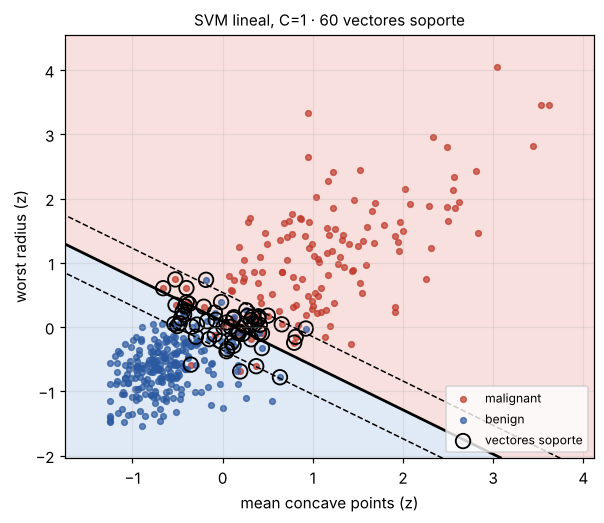

ancho del margen 2/||w|| = 0.740  (en unidades estandarizadas)
exactitud en prueba con solo 2 variables: 0.924


In [5]:
nombres = list(datos.feature_names)
cols = [nombres.index('mean concave points'), nombres.index('worst radius')]
esc2 = StandardScaler().fit(Xtr[:, cols])
A, B = esc2.transform(Xtr[:, cols]), esc2.transform(Xte[:, cols])

def dibujar(ax, modelo, A, y, titulo, margen=True):
    x0, x1 = A[:, 0].min() - .5, A[:, 0].max() + .5
    y0, y1 = A[:, 1].min() - .5, A[:, 1].max() + .5
    gx, gy = np.meshgrid(np.linspace(x0, x1, 300), np.linspace(y0, y1, 300))
    f = modelo.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx, gy, f, levels=[-99, 0, 99], colors=['#f4c7c3', '#c8d8f0'], alpha=.55)
    ax.contour(gx, gy, f, levels=[0], colors='k', linewidths=1.8)
    if margen:
        ax.contour(gx, gy, f, levels=[-1, 1], colors='k', linewidths=1, linestyles='--')
    for clase, color in [(0, '#c0392b'), (1, '#2c5aa0')]:
        ax.scatter(*A[y == clase].T, s=14, c=color, alpha=.7, label=datos.target_names[clase])
    sv = modelo.support_vectors_
    ax.scatter(*sv.T, s=90, facecolors='none', edgecolors='k', linewidths=1.2, label='vectores soporte')
    ax.set_title(titulo, fontsize=10); ax.set_xlabel('mean concave points (z)'); ax.set_ylabel('worst radius (z)')
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)

lineal = SVC(kernel='linear', C=1).fit(A, ytr)
fig, ax = plt.subplots(figsize=(6.2, 5))
dibujar(ax, lineal, A, ytr, f'SVM lineal, C=1 · {lineal.n_support_.sum()} vectores soporte')
ax.legend(loc='lower right', fontsize=8); plt.show()

w = lineal.coef_[0]
print(f'ancho del margen 2/||w|| = {2 / np.linalg.norm(w):.3f}  (en unidades estandarizadas)')
print(f'exactitud en prueba con solo 2 variables: {lineal.score(B, yte):.3f}')

**Qué observar.**
- **Línea continua**: frontera, f(x)=0. **Líneas punteadas**: f(x)=±1, los bordes del margen.
- Los **círculos** (vectores soporte) están en la franja del margen o dentro de ella, es decir, en la zona donde se tocan las clases. Los puntos lejanos no tienen círculo: tienen α=0 y **no influyen** en la solución.
- Con solo 2 variables ya se logra ≈0,92 de exactitud; con las 30, 0,953.

## Paso 5. Efecto de C
**Objetivo.** Ver cómo C cambia el margen y el número de vectores soporte (láminas 25–27). Recordatorio: en scikit-learn, **C grande penaliza más las violaciones del margen**.

**Predicción.** Si C → 0, ¿el margen se ensancha o se angosta? ¿Hay más o menos vectores soporte?

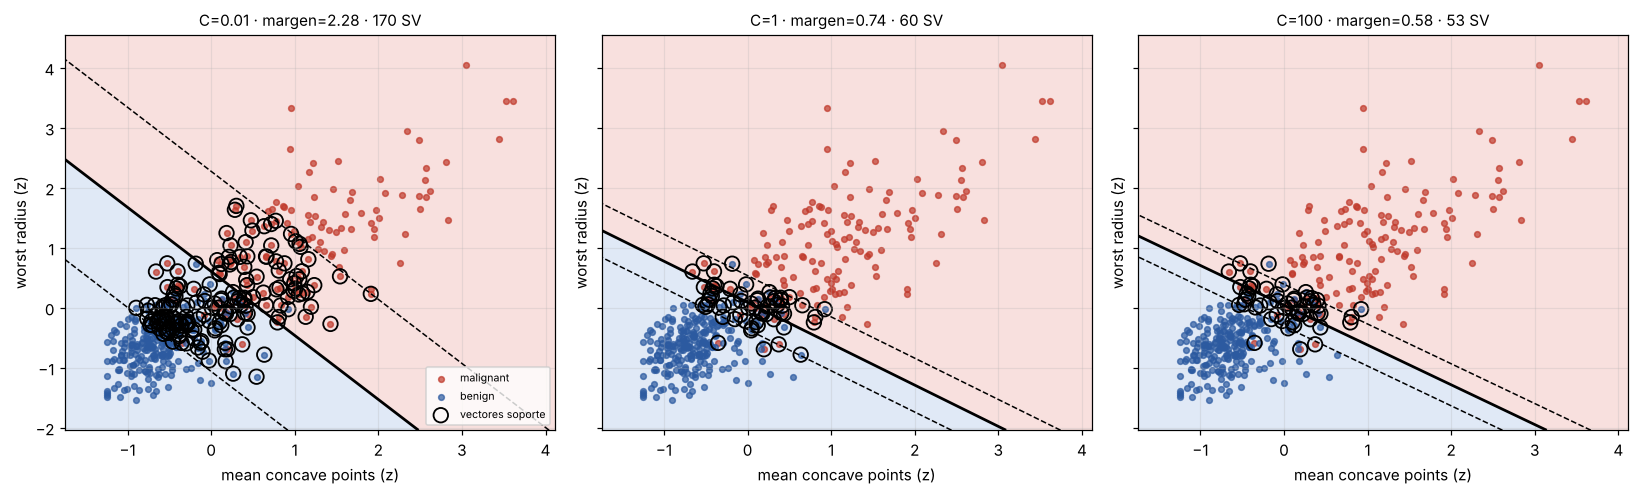

,C,ancho del margen,n° vectores soporte,exactitud prueba
0,0.01,2.281,170,0.906
1,1.00,0.740,60,0.924
2,100.00,0.584,53,0.924


In [6]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
filas = []
for ax, Cval in zip(ejes, [0.01, 1, 100]):
    m = SVC(kernel='linear', C=Cval).fit(A, ytr)
    ancho = 2 / np.linalg.norm(m.coef_)
    dibujar(ax, m, A, ytr, f'C={Cval} · margen={ancho:.2f} · {m.n_support_.sum()} SV')
    filas.append({'C': Cval, 'ancho del margen': ancho, 'n° vectores soporte': m.n_support_.sum(),
                  'exactitud prueba': m.score(B, yte)})
ejes[0].legend(loc='lower right', fontsize=7); plt.tight_layout(); plt.show()
pd.DataFrame(filas).round(3)

**Qué observar.**
- C pequeño → **margen ancho** (2,28) y **muchos** vectores soporte (170): se toleran muchas violaciones, modelo más simple.
- C grande → **margen angosto** (0,58) y **menos** vectores soporte (53): se castigan las violaciones, modelo más ajustado a los datos.
- La exactitud no cambia mucho entre C=1 y C=100: el trade-off se ve en la geometría, no necesariamente en la prueba. Por eso C se elige con validación cruzada (paso 8).

## Paso 6. El dual en acción
**Objetivo.** Comprobar con datos reales lo que dicen las láminas 19–21: la solución es una combinación de **vectores soporte**, y los multiplicadores cumplen 0 ≤ αᵢ ≤ C.

**Predicción.** En el modelo con las 30 variables, ¿cuántos de los 398 puntos de entrenamiento son vectores soporte? ¿Cuántos tendrán α = C?

In [7]:
modelo = make_pipeline(StandardScaler(), SVC(kernel='linear', C=1)).fit(Xtr, ytr)
svc = modelo[-1]
Ztr, Zte = modelo[0].transform(Xtr), modelo[0].transform(Xte)

alfa = np.abs(svc.dual_coef_[0])          # |alpha_i * y_i| = alpha_i
en_borde = np.isclose(alfa, svc.C)          # alpha = C
print(f'vectores soporte: {len(alfa)} de {len(ytr)}  ({svc.n_support_[0]} malignos + {svc.n_support_[1]} benignos)')
print(f'  alpha = C  (dentro del margen o mal clasificados): {en_borde.sum()}')
print(f'  0 < alpha < C  (exactamente sobre el margen):      {(~en_borde).sum()}')
print(f'  alpha = 0  (no influyen):                           {len(ytr) - len(alfa)}')
print('  restricción  sum(alpha_i y_i) = 0 :', np.round(svc.dual_coef_.sum(), 10))

# f(x) = sum_i alpha_i y_i <x_i, x> + b, solo con vectores soporte
K = svc.support_vectors_ @ Zte.T
f_dual = (svc.dual_coef_ @ K).ravel() + svc.intercept_[0]
print('\ndiferencia máxima con decision_function:', np.abs(f_dual - svc.decision_function(Zte)).max())

vectores soporte: 27 de 398  (14 malignos + 13 benignos)
  alpha = C  (dentro del margen o mal clasificados): 11
  0 < alpha < C  (exactamente sobre el margen):      16
  alpha = 0  (no influyen):                           371
  restricción  sum(alpha_i y_i) = 0 : -0.0

diferencia máxima con decision_function: 1.5987211554602254e-14


**Qué observar.**
- Solo **27 de 398** puntos (7 %) definen el modelo. Los otros 371 podrían eliminarse del entrenamiento y la solución sería **idéntica**.
- Hay puntos con α=C (violaciones del margen) y puntos con 0<α<C (sobre el margen): los tres tipos de la lámina 25.
- La restricción Σαᵢyᵢ=0 se cumple, y reconstruir f(x) **solo con vectores soporte** coincide con `decision_function` al nivel de error numérico. Esa es la forma kernelizada que vimos: basta cambiar ⟨xᵢ, x⟩ por k(xᵢ, x).

## Paso 7. Kernel RBF y gamma
**Objetivo.** Ver el efecto de γ sobre la frontera (lámina 28), de nuevo en 2D.

**Predicción.** Con γ muy grande, ¿la frontera será suave o muy sinuosa? ¿Cómo cambiará el número de vectores soporte?

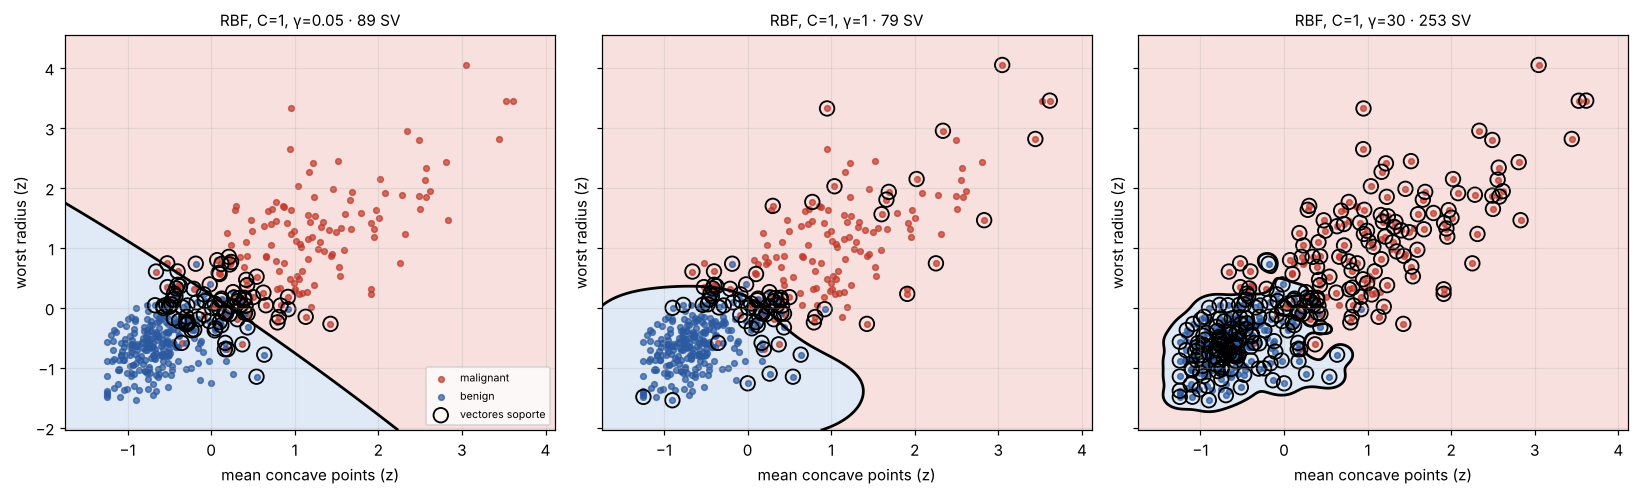

,gamma,n° vectores soporte,exactitud entrenamiento,exactitud prueba
0,0.05,89,0.935,0.906
1,1.00,79,0.945,0.918
2,30.00,253,0.970,0.901


In [8]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
filas = []
for ax, g in zip(ejes, [0.05, 1, 30]):
    m = SVC(kernel='rbf', C=1, gamma=g).fit(A, ytr)
    dibujar(ax, m, A, ytr, f'RBF, C=1, γ={g} · {m.n_support_.sum()} SV', margen=False)
    filas.append({'gamma': g, 'n° vectores soporte': m.n_support_.sum(),
                  'exactitud entrenamiento': m.score(A, ytr), 'exactitud prueba': m.score(B, yte)})
ejes[0].legend(loc='lower right', fontsize=7); plt.tight_layout(); plt.show()
pd.DataFrame(filas).round(3)

**Qué observar.**
- γ pequeño (0,05): frontera casi lineal.
- γ grande (30): la frontera rodea puntos individuales; 253 de los 398 puntos (64 %) son vectores soporte, frente a 79–89 con γ menor.
- La señal de **sobreajuste** es que el entrenamiento sube (0,970) mientras la prueba baja (0,901). Con solo 2 variables y 171 casos las diferencias son modestas (≈3 pacientes): lo importante es la tendencia, no el valor exacto.

## Paso 8. Elegir C y gamma con validación cruzada
**Objetivo.** Elegir los hiperparámetros **sin tocar el conjunto de prueba**, usando `GridSearchCV` sobre un `Pipeline` con grilla logarítmica.

**Predicción.** ¿Qué combinación de (C, γ) ganará? ¿Habrá celdas con exactitud cercana a la línea base 0,626?

mejores parámetros: {'svc__C': 100, 'svc__gamma': 0.001}
exactitud CV (5 pliegues): 0.985


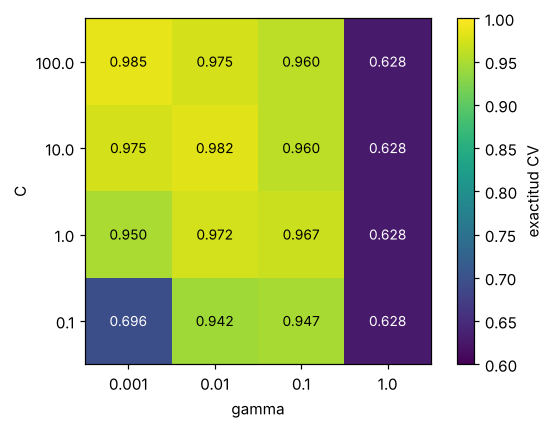

In [9]:
pipe = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
grilla = {'svc__C': [0.1, 1, 10, 100], 'svc__gamma': [1e-3, 1e-2, 1e-1, 1]}
busqueda = GridSearchCV(pipe, grilla, cv=5).fit(Xtr, ytr)

print('mejores parámetros:', busqueda.best_params_)
print(f'exactitud CV (5 pliegues): {busqueda.best_score_:.3f}')

tabla = pd.DataFrame(busqueda.cv_results_['mean_test_score'].reshape(4, 4),
                     index=grilla['svc__C'], columns=grilla['svc__gamma'])
fig, ax = plt.subplots(figsize=(5.5, 4))
im = ax.imshow(tabla.values, cmap='viridis', origin='lower', vmin=.6, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(tabla.columns); ax.set_yticks(range(4)); ax.set_yticklabels(tabla.index)
ax.set_xlabel('gamma'); ax.set_ylabel('C'); ax.grid(False)
for (i, j), v in np.ndenumerate(tabla.values):
    ax.text(j, i, f'{v:.3f}', ha='center', va='center', color='w' if v < .9 else 'k', fontsize=9)
plt.colorbar(im, label='exactitud CV'); plt.tight_layout(); plt.show()

**Qué observar.**
- Gana **C=100, γ=0,001** con 0,985 de exactitud CV: un kernel casi lineal con penalización fuerte.
- La columna γ=1 queda en 0,628: prácticamente la línea base. Y la fila C=0,1 con γ=0,001 baja a 0,696: poca penalización y alcance muy amplio dan un modelo demasiado rígido. Con 30 variables estandarizadas y γ=1, el kernel entre dos puntos distintos es casi 0, el modelo memoriza el entrenamiento y no generaliza.
- Compare con el kernel lineal en validación cruzada (siguiente celda): la diferencia es del orden del ruido.

In [10]:
lin_cv = cross_val_score(make_pipeline(StandardScaler(), SVC(kernel='linear')), Xtr, ytr, cv=5)
print(f'lineal (C=1), CV:   {lin_cv.mean():.3f} ± {lin_cv.std():.3f}')
print(f'RBF optimizado, CV: {busqueda.best_score_:.3f}')

lineal (C=1), CV:   0.975 ± 0.018
RBF optimizado, CV: 0.985


## Paso 9. Evaluación final (una sola vez)
**Objetivo.** Usar el conjunto de prueba **una única vez**, con el modelo ya elegido, y mirar más que la exactitud: en un problema clínico importan los **errores de cada tipo**.

**Predicción.** ¿Qué es peor aquí, un falso negativo (maligno clasificado como benigno) o un falso positivo?

exactitud en prueba: 0.953   (línea base: 0.626)

              precision    recall  f1-score   support

   malignant      0.952     0.922     0.937        64
      benign      0.954     0.972     0.963       107

    accuracy                          0.953       171
   macro avg      0.953     0.947     0.950       171
weighted avg      0.953     0.953     0.953       171



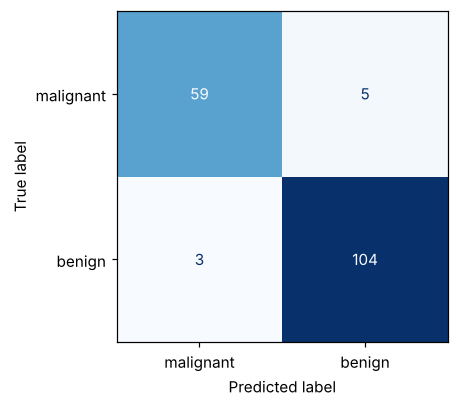

In [11]:
mejor = busqueda.best_estimator_
pred = mejor.predict(Xte)
print(f'exactitud en prueba: {mejor.score(Xte, yte):.3f}   (línea base: {base:.3f})\n')
print(classification_report(yte, pred, target_names=datos.target_names, digits=3))

fig, ax = plt.subplots(figsize=(4.2, 3.8))
ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=datos.target_names).plot(ax=ax, colorbar=False, cmap='Blues')
ax.grid(False); plt.tight_layout(); plt.show()

**Qué observar.**
- Exactitud en prueba **0,953**, por debajo de la CV (0,985). Parte de esa brecha es esperable: la CV se usó para *elegir* la mejor combinación, así que su valor es algo optimista, y con 171 casos la prueba tiene incertidumbre propia (≈5 pacientes de diferencia).
- De 64 tumores malignos, **5 se clasificaron como benignos** (recall 0,92). En diagnóstico, el falso negativo es el error más costoso; esto se podría mitigar con `class_weight` o ajustando el umbral de `decision_function`, a costa de más falsos positivos.
- Con 171 casos, cada paciente son ≈0,6 puntos de exactitud. Para comparar modelos con rigor, repetir con varias particiones (ver tarea B5).

### Resumen
1. **Estandarizar** dentro de un `Pipeline` siempre.
2. La solución de la SVM depende solo de los **vectores soporte** (7 % de los datos en este ejemplo).
3. **C** controla el ancho del margen; **γ** el alcance de cada punto. Se eligen **juntos** por validación cruzada en grilla logarítmica.
4. Antes de usar un kernel complejo, **comparar con el lineal** y con la línea base.
5. Reportar el conjunto de prueba **una vez**, y mirar los errores por clase.